#Preparation & Eksplorasi Data (EDA)

In [ ]:
import os
dataset_path = extraction_path

# Filter for actual cloud class directories
cloud_class_directories = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d)) and d.startswith('clouds_')]

# Create an empty dictionary to store image counts per class
image_counts_filtered = {}

print("Jumlah gambar per kelas (hanya kelas awan):")
for class_name in sorted(cloud_class_directories):
    class_path = os.path.join(dataset_path, class_name)
    num_images = len(os.listdir(class_path))
    image_counts_filtered[class_name] = num_images
    print(f"- {class_name}: {num_images} gambar")

print(f"\nJumlah total kelas awan yang teridentifikasi: {len(image_counts_filtered)}")

Jumlah gambar per kelas (hanya kelas awan):
- clouds_test: 7 gambar
- clouds_train: 7 gambar

Jumlah total kelas awan yang teridentifikasi: 2


## Visualisasi Contoh Gambar dan Distribusi Kelas


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Initialize dictionary to store image counts per cloud type
cloud_type_image_counts = {}

# Initialize list to store one example image path for each unique cloud type
example_images_data = []

# Keep track of collected example cloud types to avoid duplicates
collected_example_cloud_types = set()

# Define the primary cloud datasets (from previous steps, these are 'clouds_train' and 'clouds_test')
primary_datasets = ['clouds_train', 'clouds_test']

# Loop through each primary cloud dataset
for primary_dataset_name in primary_datasets:
    primary_dataset_path = os.path.join(extraction_path, primary_dataset_name)

    # Get subdirectories (actual cloud types) within this primary dataset
    cloud_types_in_dataset = [d for d in os.listdir(primary_dataset_path) if os.path.isdir(os.path.join(primary_dataset_path, d))]

    for cloud_type in cloud_types_in_dataset:
        cloud_type_path = os.path.join(primary_dataset_path, cloud_type)

        # List all image files in the current cloud type directory
        image_files = [f for f in os.listdir(cloud_type_path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp'))]
        num_images = len(image_files)

        # Update cloud_type_image_counts
        cloud_type_image_counts[cloud_type] = cloud_type_image_counts.get(cloud_type, 0) + num_images

        # Collect one example image for this cloud type if not already collected
        if cloud_type not in collected_example_cloud_types and num_images > 0:
            example_image_path = os.path.join(cloud_type_path, image_files[0])
            example_images_data.append({'cloud_type': cloud_type, 'path': example_image_path})
            collected_example_cloud_types.add(cloud_type)

print("Data collection for example images and class distribution complete.")
print(f"Total unique cloud types found: {len(cloud_type_image_counts)}")
print("Collected example image paths:")
for item in example_images_data:
    print(f"  - {item['cloud_type']}: {item['path']}")

Data collection for example images and class distribution complete.
Total unique cloud types found: 7
Collected example image paths:
  - clear sky: ./clouds_train/clear sky/13947b8d0ed983756ca3a0cab6ad6ecb.jpg
  - cirriform clouds: ./clouds_train/cirriform clouds/55020be2b80166681d74e5a3e1fed38f.jpg
  - cumulonimbus clouds: ./clouds_train/cumulonimbus clouds/dd9e6fb53af8099a5c96ff212ccf627c.jpg
  - stratocumulus clouds: ./clouds_train/stratocumulus clouds/6396feef6b2e3651aa6d16390a362996.jpg
  - cumulus clouds: ./clouds_train/cumulus clouds/ac2e14a7bb8684cc5d51f94a9fccb5e5.jpg
  - high cumuliform clouds: ./clouds_train/high cumuliform clouds/e31a175ca50534a127ecdaca80f9bd66.jpg
  - stratiform clouds: ./clouds_train/stratiform clouds/b5cfc09cbe0d31e3d5b2d32752d8d9c1.jpg


Menampilkan contoh gambar untuk setiap jenis awan:


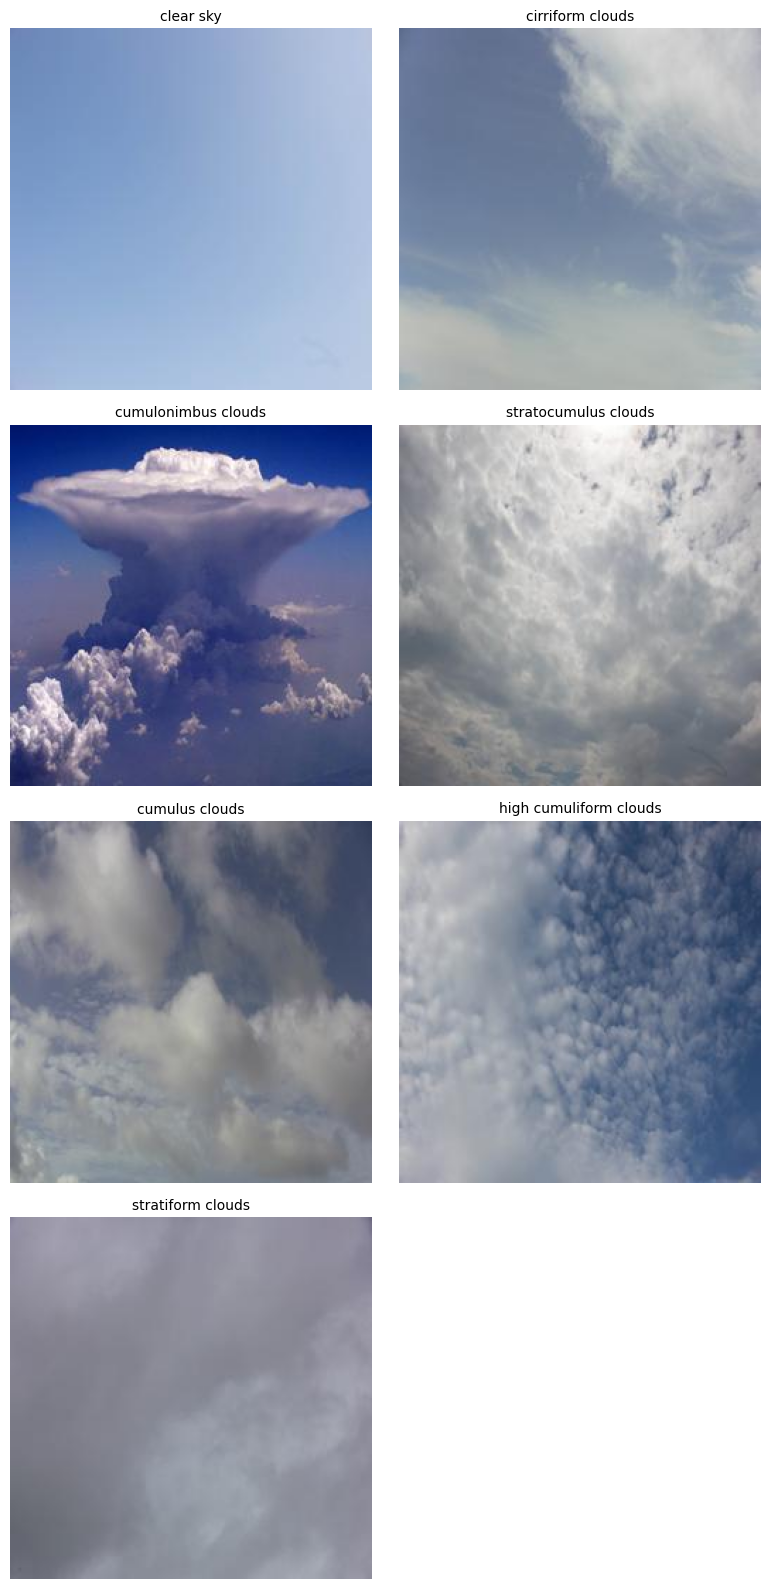

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

num_examples = len(example_images_data)

n_cols = int(num_examples**0.5) if num_examples > 0 else 1
n_rows = (num_examples + n_cols - 1) // n_cols

plt.figure(figsize=(n_cols * 4, n_rows * 4))

print("Menampilkan contoh gambar untuk setiap jenis awan:")
for i, item in enumerate(example_images_data):
    plt.subplot(n_rows, n_cols, i + 1)
    try:
        img = Image.open(item['path'])
        plt.imshow(img)
        plt.title(item['cloud_type'], fontsize=10)
        plt.axis('off')
    except FileNotFoundError:
        print(f"Gambar tidak ditemukan: {item['path']}")
    except Exception as e:
        print(f"Gagal memuat gambar {item['path']}: {e}")

plt.tight_layout()
plt.show()

## Visualisasi Distribusi Kelas Awan

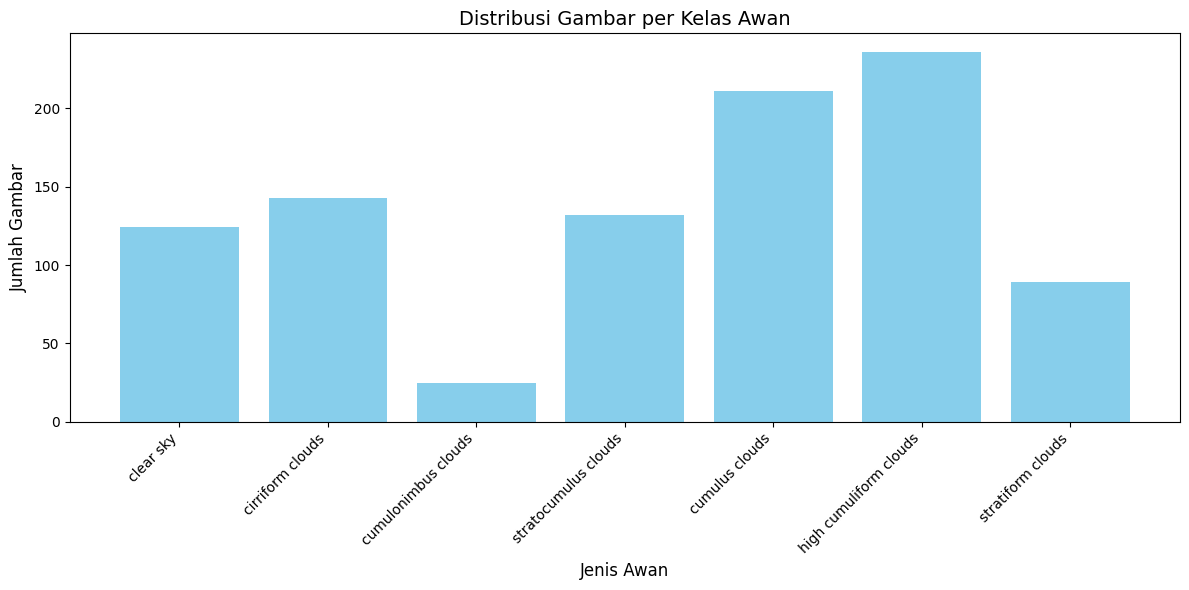

In [ ]:
import matplotlib.pyplot as plt

# 1. Ekstrak nama-nama kelas awan dan jumlah gambar
cloud_types = list(cloud_type_image_counts.keys())
image_counts = list(cloud_type_image_counts.values())

# 2. Buat diagram batang
plt.figure(figsize=(12, 6))
plt.bar(cloud_types, image_counts, color='skyblue')

# 3. Tambahkan label pada sumbu x dan y
plt.xlabel('Jenis Awan', fontsize=12)
plt.ylabel('Jumlah Gambar', fontsize=12)

# 4. Beri judul pada plot
plt.title('Distribusi Gambar per Kelas Awan', fontsize=14)

# 5. Rotasi label sumbu x jika diperlukan agar mudah dibaca
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

# 6. Tambahkan plt.tight_layout() untuk menyesuaikan tata letak plot
plt.tight_layout()
plt.show()

#Data Preprocessing

## Resize


In [ ]:
import numpy as np
from PIL import Image
import os

# 1. Inisialisasi dua list kosong
X_resized = []
y_labels = []

# 2. Tentukan ukuran target untuk resizing
IMG_SIZE = (128, 128)

print(f"Memulai proses resize citra menjadi {IMG_SIZE[0]}x{IMG_SIZE[1]} piksel...")

# Loop through the primary datasets (clouds_train and clouds_test) to get all image paths
for primary_dataset_name in primary_datasets:
    primary_dataset_path = os.path.join(extraction_path, primary_dataset_name)

    # Get subdirectories (actual cloud types) within this primary dataset
    cloud_types_in_dataset = [d for d in os.listdir(primary_dataset_path) if os.path.isdir(os.path.join(primary_dataset_path, d))]

    # 3. Iterasi melalui setiap jenis awan
    for cloud_type in cloud_types_in_dataset:
        cloud_type_path = os.path.join(primary_dataset_path, cloud_type)

        # 5. Di dalam setiap direktori jenis awan, iterasi melalui setiap file gambar.
        for image_file in os.listdir(cloud_type_path):
            if image_file.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp')):
                image_path = os.path.join(cloud_type_path, image_file)
                try:
                    # 6. Muat setiap gambar
                    img = Image.open(image_path)

                    # 7. Ubah ukuran gambar
                    img_resized = img.resize(IMG_SIZE)

                    # 8. Konversi gambar yang telah diresize ke dalam array NumPy
                    img_array = np.array(img_resized)

                    # 9. Tambahkan array gambar yang telah diresize ke list X_resized
                    X_resized.append(img_array)

                    # 10. Tambahkan nama jenis awan (label) yang sesuai ke list y_labels
                    y_labels.append(cloud_type)
                except Exception as e:
                    print(f"Gagal memproses gambar {image_path}: {e}")

print(f"Proses resize selesai. Jumlah gambar yang diresize: {len(X_resized)}")
print(f"Jumlah label yang terkumpul: {len(y_labels)}")


Memulai proses resize citra menjadi 128x128 piksel...
Proses resize selesai. Jumlah gambar yang diresize: 960
Jumlah label yang terkumpul: 960


## Normalisasi Piksel


In [ ]:
X_resized_np = np.array(X_resized).astype('float32')
X_normalized = X_resized_np / 255.0

print(f"Bentuk array gambar yang dinormalisasi: {X_normalized.shape}")
print(f"Rentang nilai piksel setelah normalisasi: {X_normalized.min()} - {X_normalized.max()}")

Bentuk array gambar yang dinormalisasi: (960, 128, 128, 3)
Rentang nilai piksel setelah normalisasi: 0.0 - 1.0


## Label Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder

# 2. Buat instance LabelEncoder
label_encoder = LabelEncoder()

# 3. Terapkan fit_transform pada y_labels
y_encoded = label_encoder.fit_transform(y_labels)

print("Label encoding berhasil dilakukan.")
print("\nBeberapa label asli dan yang sudah di-encode:")
for i in range(5):
    print(f"Original: {y_labels[i]}, Encoded: {y_encoded[i]}")

print("\nDaftar kelas yang ditemukan oleh encoder:")
print(label_encoder.classes_)


Label encoding berhasil dilakukan.

Beberapa label asli dan yang sudah di-encode:
Original: clear sky, Encoded: 1
Original: clear sky, Encoded: 1
Original: clear sky, Encoded: 1
Original: clear sky, Encoded: 1
Original: clear sky, Encoded: 1

Daftar kelas yang ditemukan oleh encoder:
['cirriform clouds' 'clear sky' 'cumulonimbus clouds' 'cumulus clouds'
 'high cumuliform clouds' 'stratiform clouds' 'stratocumulus clouds']


## Membagi Dataset Menjadi Set Pelatihan dan Pengujian


In [ ]:
from sklearn.model_selection import train_test_split

# 2. Tentukan ukuran set pengujian
test_size = 0.2

# 3. Gunakan random_state untuk reproduksi
random_state = 42

print(f"Membagi dataset menjadi set pelatihan dan pengujian dengan test_size={test_size} dan random_state={random_state}...")

# 4. Terapkan train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_encoded, test_size=test_size, random_state=random_state, stratify=y_encoded)

# 6. Cetak bentuk (shape) dari setiap set
print(f"Bentuk X_train: {X_train.shape}")
print(f"Bentuk X_test: {X_test.shape}")
print(f"Bentuk y_train: {y_train.shape}")
print(f"Bentuk y_test: {y_test.shape}")

Membagi dataset menjadi set pelatihan dan pengujian dengan test_size=0.2 dan random_state=42...
Bentuk X_train: (768, 128, 128, 3)
Bentuk X_test: (192, 128, 128, 3)
Bentuk y_train: (768,)
Bentuk y_test: (192,)


## Flattening Images for Traditional ML Models

In [ ]:
num_channels = X_normalized.shape[3] # Get the number of channels (e.g., 3 for RGB)
total_features = IMG_SIZE[0] * IMG_SIZE[1] * num_channels

print(f"Jumlah total fitur per gambar: {total_features}")

# Reshape X_train
X_train_flat = X_train.reshape(X_train.shape[0], total_features)

# Reshape X_test
X_test_flat = X_test.reshape(X_test.shape[0], total_features)

print(f"Bentuk X_train_flat setelah flattening: {X_train_flat.shape}")
print(f"Bentuk X_test_flat setelah flattening: {X_test_flat.shape}")

Jumlah total fitur per gambar: 49152
Bentuk X_train_flat setelah flattening: (768, 49152)
Bentuk X_test_flat setelah flattening: (192, 49152)


## Reduksi Dimensi dengan PCA

In [ ]:
from sklearn.decomposition import PCA

# 2. Inisialisasi objek PCA
# Mempertahankan 95% variansi
pca = PCA(n_components=0.95)

print(f"Melakukan PCA pada data pelatihan dan pengujian dengan mempertahankan 95% variansi...")

# 3. Terapkan fit PCA pada X_train_flat
pca.fit(X_train_flat)

# 4. Terapkan transform PCA pada X_train_flat dan X_test_flat
X_train_pca = pca.transform(X_train_flat)
X_test_pca = pca.transform(X_test_flat)

print(f"Jumlah komponen yang dipilih oleh PCA: {pca.n_components_}")
print(f"Bentuk X_train_pca setelah reduksi dimensi: {X_train_pca.shape}")
print(f"Bentuk X_test_pca setelah reduksi dimensi: {X_test_pca.shape}")

Melakukan PCA pada data pelatihan dan pengujian dengan mempertahankan 95% variansi...
Jumlah komponen yang dipilih oleh PCA: 115
Bentuk X_train_pca setelah reduksi dimensi: (768, 115)
Bentuk X_test_pca setelah reduksi dimensi: (192, 115)


## One-Hot Encoding Labels for CNN Models

In [ ]:
from tensorflow.keras.utils import to_categorical

# 2. Terapkan to_categorical pada y_train
y_train_one_hot = to_categorical(y_train)

# 3. Terapkan to_categorical pada y_test
y_test_one_hot = to_categorical(y_test)

print(f"Bentuk y_train_one_hot: {y_train_one_hot.shape}")
print(f"Bentuk y_test_one_hot: {y_test_one_hot.shape}")

Bentuk y_train_one_hot: (768, 7)
Bentuk y_test_one_hot: (192, 7)


## Training Model SVM


In [ ]:
from sklearn.svm import SVC

svm_model = SVC(kernel='rbf', C=1.0, random_state=42)

#Train the SVM model
svm_model.fit(X_train_pca, y_train)

Memulai pelatihan model SVM...
Pelatihan model SVM selesai.


## Evaluasi Model SVM

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred_svm = svm_model.predict(X_test_pca)

# Calculate and print accuracy
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f"Akurasi Model SVM: {accuracy_svm:.4f}")

# Calculate and print precision, recall, and F1-score
# Using 'weighted' average for multi-class classification to account for class imbalance
precision_svm = precision_score(y_test, y_pred_svm, average='weighted')
recall_svm = recall_score(y_test, y_pred_svm, average='weighted')
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')

print(f"Presisi Model SVM (weighted): {precision_svm:.4f}")
print(f"Recall Model SVM (weighted): {recall_svm:.4f}")
print(f"F1-Score Model SVM (weighted): {f1_svm:.4f}")

Membuat prediksi menggunakan model SVM...
Mengevaluasi kinerja model SVM...
Akurasi Model SVM: 0.5833
Presisi Model SVM (weighted): 0.5927
Recall Model SVM (weighted): 0.5833
F1-Score Model SVM (weighted): 0.5767


## Training Model Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

#Train the Random Forest model
rf_model.fit(X_train_flat, y_train)

Memulai pelatihan model Random Forest...
Pelatihan model Random Forest selesai.


## Evaluasi Model Random Forest

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred_rf = rf_model.predict(X_test_flat)
# Calculate and print accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Akurasi Model Random Forest: {accuracy_rf:.4f}")

# Calculate and print precision, recall, and F1-score
# Using 'weighted' average for multi-class classification to account for class imbalance
precision_rf = precision_score(y_test, y_pred_rf, average='weighted')
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

print(f"Presisi Model Random Forest (weighted): {precision_rf:.4f}")
print(f"Recall Model Random Forest (weighted): {recall_rf:.4f}")
print(f"F1-Score Model Random Forest (weighted): {f1_rf:.4f}")

Membuat prediksi menggunakan model Random Forest...
Mengevaluasi kinerja model Random Forest...
Akurasi Model Random Forest: 0.5625
Presisi Model Random Forest (weighted): 0.5737
Recall Model Random Forest (weighted): 0.5625
F1-Score Model Random Forest (weighted): 0.5547


## Training Model CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# 2. Tentukan bentuk input berdasarkan data X_train
input_shape = X_train.shape[1:]
num_classes = y_train_one_hot.shape[1]

print(f"Bentuk input untuk CNN: {input_shape}")
print(f"Jumlah kelas untuk output CNN: {num_classes}")

# 3. Bangun model Sequential
cnn_model = Sequential([
    # Layer Konvolusi 1
    Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
    MaxPooling2D((2, 2)),

    # Layer Konvolusi 2
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Layer Konvolusi 3
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Flattening untuk lapisan Dense
    Flatten(),

    # Layer Dense
    Dense(128, activation='relu'),
    Dropout(0.5), # Tambahkan Dropout untuk regulasi

    # Output Layer
    Dense(num_classes, activation='softmax')
])

# 4. Kompilasi model
cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Model CNN berhasil dibangun dan dikompilasi.")
cnn_model.summary()


Bentuk input untuk CNN: (128, 128, 3)
Jumlah kelas untuk output CNN: 7
Model CNN berhasil dibangun dan dikompilasi.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,543 (12.61 MB)

 Trainable params: 3,305,543 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = cnn_model.fit(
    X_train,
    y_train_one_hot,
    epochs=20, # You can adjust the number of epochs
    batch_size=32, # You can adjust the batch size
    validation_split=0.2, # Use a portion of training data for validation
    verbose=1
)

Memulai pelatihan model CNN...
Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.2200 - loss: 1.9396 - val_accuracy: 0.2987 - val_loss: 1.7420
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.3314 - loss: 1.6818 - val_accuracy: 0.3506 - val_loss: 1.5230
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.3867 - loss: 1.5112 - val_accuracy: 0.3117 - val_loss: 1.7722
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.3304 - loss: 1.6182 - val_accuracy: 0.3506 - val_loss: 1.5002
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.3915 - loss: 1.5051 - val_accuracy: 0.3701 - val_loss: 1.3181
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.4715 - loss: 1.3558 - val_accuracy: 0.3636 - val_loss: 1.3245
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.4738 - loss: 1.3120 - val_accuracy: 0.4481 - val_loss: 1.3065
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.4611 - loss: 1.2875 - v

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

print("Mengevaluasi kinerja model CNN pada data pengujian...")

# Evaluate the CNN model on the test data
loss_cnn, accuracy_cnn = cnn_model.evaluate(X_test, y_test_one_hot, verbose=0)

print(f"Akurasi Model CNN: {accuracy_cnn:.4f}")

# Make predictions for precision, recall, F1-score
y_pred_cnn_probs = cnn_model.predict(X_test)
y_pred_cnn = np.argmax(y_pred_cnn_probs, axis=1)

# Convert y_test_one_hot back to class labels for comparison with y_pred_cnn
y_test_labels = np.argmax(y_test_one_hot, axis=1)

# Calculate and print precision, recall, and F1-score
# Using 'weighted' average for multi-class classification to account for class imbalance
precision_cnn = precision_score(y_test_labels, y_pred_cnn, average='weighted')
recall_cnn = recall_score(y_test_labels, y_pred_cnn, average='weighted')
f1_cnn = f1_score(y_test_labels, y_pred_cnn, average='weighted')

print(f"Presisi Model CNN (weighted): {precision_cnn:.4f}")
print(f"Recall Model CNN (weighted): {recall_cnn:.4f}")
print(f"F1-Score Model CNN (weighted): {f1_cnn:.4f}")

Mengevaluasi kinerja model CNN pada data pengujian...
Akurasi Model CNN: 0.5677
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 279ms/step
Presisi Model CNN (weighted): 0.5523
Recall Model CNN (weighted): 0.5677
F1-Score Model CNN (weighted): 0.5248


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Perbandingan Kinerja Model

| Model          | Akurasi  | Presisi (weighted) | Recall (weighted) | F1-Score (weighted) |
| :------------- | :------- | :----------------- | :---------------- | :------------------ |
| **SVM**        | 0.5833 | 0.5927      | 0.5833    | 0.5767      |
| **Random Forest** | 0.5625 | 0.5737      | 0.5625    | 0.5547       |
| **CNN**        | 0.5677 | 0.5523      | 0.5677    | 0.5248      |

**Analisis Perbandingan:**

*   **Akurasi:**
    *   SVM menunjukkan akurasi tertinggi.
    *   CNN berada di posisi kedua, diikuti oleh Random Forest.

*   **Presisi, Recall, dan F1-Score (Weighted):**
    *   Mirip dengan akurasi, SVM umumnya memiliki nilai tertinggi untuk presisi, recall, dan F1-score.
    *   CNN dan Random Forest memiliki kinerja yang relatif berdekatan pada metrik ini, dengan CNN sedikit lebih unggul dalam beberapa kasus.

**Kesimpulan Awal:**

Berdasarkan metrik evaluasi ini, **model SVM** memberikan kinerja terbaik di antara ketiga model untuk klasifikasi gambar awan pada dataset ini. Ini mungkin disebabkan oleh efektifitas PCA dalam mereduksi dimensi data, yang membantu SVM bekerja lebih baik dengan fitur-fitur yang lebih ringkas dan penting. Namun, penting untuk dicatat bahwa kinerja dapat bervariasi dengan tuning hyperparameter yang lebih lanjut atau dengan dataset yang berbeda.

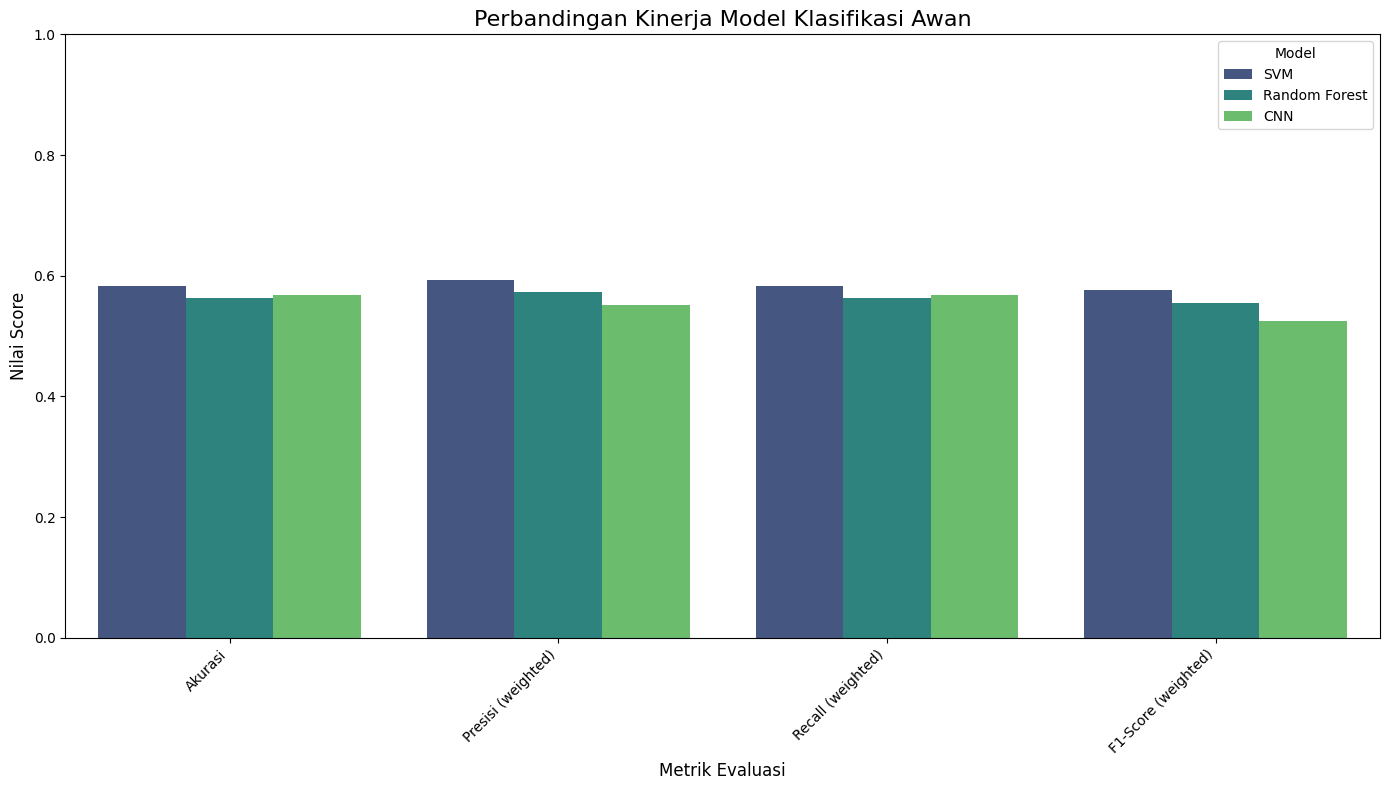

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data perbandingan model
model_comparison_data = {
    'Model': ['SVM', 'Random Forest', 'CNN'],
    'Akurasi': [accuracy_svm, accuracy_rf, accuracy_cnn],
    'Presisi (weighted)': [precision_svm, precision_rf, precision_cnn],
    'Recall (weighted)': [recall_svm, recall_rf, recall_cnn],
    'F1-Score (weighted)': [f1_svm, f1_rf, f1_cnn]
}

df_comparison = pd.DataFrame(model_comparison_data)

# Melt DataFrame untuk plot batang yang lebih baik
df_melted = df_comparison.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(14, 8))
sns.barplot(x='Metric', y='Score', hue='Model', data=df_melted, palette='viridis')
plt.title('Perbandingan Kinerja Model Klasifikasi Awan', fontsize=16)
plt.xlabel('Metrik Evaluasi', fontsize=12)
plt.ylabel('Nilai Score', fontsize=12)
plt.ylim(0, 1) # Skala Y dari 0 ke 1 untuk metrik
plt.xticks(rotation=45, ha='right')
plt.legend(title='Model')
plt.tight_layout()
plt.show()

## Hyperparameter Tuning for SVM


In [ ]:
from sklearn.model_selection import GridSearchCV

# 2. Define a parameter grid for SVC
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

print("Memulai pencarian hyperparameter untuk SVM menggunakan GridSearchCV...")

# 3. Create an instance of GridSearchCV
grid_search_svm = GridSearchCV(SVC(random_state=42), param_grid, cv=5, verbose=2, n_jobs=-1)

# 4. Fit the GridSearchCV object to the PCA-transformed training data
grid_search_svm.fit(X_train_pca, y_train)

print("Pencarian hyperparameter selesai.")

# 5. Print the best parameters found by GridSearchCV
print(f"Parameter terbaik: {grid_search_svm.best_params_}")

# 6. Print the best cross-validation score achieved by GridSearchCV
print(f"Skor cross-validasi terbaik: {grid_search_svm.best_score_:.4f}")

Memulai pencarian hyperparameter untuk SVM menggunakan GridSearchCV...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Pencarian hyperparameter selesai.
Parameter terbaik: {'C': 10, 'kernel': 'rbf'}
Skor cross-validasi terbaik: 0.5937


In [ ]:
tuned_svm_model = grid_search_svm.best_estimator_

print("Model SVM yang telah dituning berhasil diinisialisasi.")

Model SVM yang telah dituning berhasil diinisialisasi.


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Membuat prediksi menggunakan model SVM yang telah dituning...")
y_pred_tuned_svm = tuned_svm_model.predict(X_test_pca)

print("Mengevaluasi kinerja model SVM yang telah dituning...")
# Calculate and print accuracy
accuracy_tuned_svm = accuracy_score(y_test, y_pred_tuned_svm)
print(f"Akurasi Model SVM (tuned): {accuracy_tuned_svm:.4f}")

# Calculate and print precision, recall, and F1-score
# Using 'weighted' average for multi-class classification to account for class imbalance
precision_tuned_svm = precision_score(y_test, y_pred_tuned_svm, average='weighted')
recall_tuned_svm = recall_score(y_test, y_pred_tuned_svm, average='weighted')
f1_tuned_svm = f1_score(y_test, y_pred_tuned_svm, average='weighted')

print(f"Presisi Model SVM (tuned, weighted): {precision_tuned_svm:.4f}")
print(f"Recall Model SVM (tuned, weighted): {recall_tuned_svm:.4f}")
print(f"F1-Score Model SVM (tuned, weighted): {f1_tuned_svm:.4f}")

Membuat prediksi menggunakan model SVM yang telah dituning...
Mengevaluasi kinerja model SVM yang telah dituning...
Akurasi Model SVM (tuned): 0.6198
Presisi Model SVM (tuned, weighted): 0.6229
Recall Model SVM (tuned, weighted): 0.6198
F1-Score Model SVM (tuned, weighted): 0.6150


## Hyperparameter Tuning for Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# 2. Define a parameter grid for RandomForestClassifier
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20]
}

print("Memulai pencarian hyperparameter untuk Random Forest menggunakan GridSearchCV...")

# 3. Create an instance of GridSearchCV
grid_search_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, verbose=2, n_jobs=-1)

# 4. Fit the GridSearchCV object to the flattened training data
grid_search_rf.fit(X_train_flat, y_train)

print("Pencarian hyperparameter Random Forest selesai.")

# 5. Print the best parameters found by GridSearchCV
print(f"Parameter terbaik untuk Random Forest: {grid_search_rf.best_params_}")

# 6. Print the best cross-validation score achieved by GridSearchCV
print(f"Skor cross-validasi terbaik untuk Random Forest: {grid_search_rf.best_score_:.4f}")

Memulai pencarian hyperparameter untuk Random Forest menggunakan GridSearchCV...
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Pencarian hyperparameter Random Forest selesai.
Parameter terbaik untuk Random Forest: {'max_depth': None, 'n_estimators': 50}
Skor cross-validasi terbaik untuk Random Forest: 0.5755


In [ ]:
tuned_rf_model = grid_search_rf.best_estimator_

print("Model Random Forest yang telah dituning berhasil diinisialisasi.")

Model Random Forest yang telah dituning berhasil diinisialisasi.


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Membuat prediksi menggunakan model Random Forest yang telah dituning...")
y_pred_tuned_rf = tuned_rf_model.predict(X_test_flat)

print("Mengevaluasi kinerja model Random Forest yang telah dituning...")
# Calculate and print accuracy
accuracy_tuned_rf = accuracy_score(y_test, y_pred_tuned_rf)
print(f"Akurasi Model Random Forest (tuned): {accuracy_tuned_rf:.4f}")

# Calculate and print precision, recall, and F1-score
# Using 'weighted' average for multi-class classification to account for class imbalance
precision_tuned_rf = precision_score(y_test, y_pred_tuned_rf, average='weighted')
recall_tuned_rf = recall_score(y_test, y_pred_tuned_rf, average='weighted')
f1_tuned_rf = f1_score(y_test, y_pred_tuned_rf, average='weighted')

print(f"Presisi Model Random Forest (tuned, weighted): {precision_tuned_rf:.4f}")
print(f"Recall Model Random Forest (tuned, weighted): {recall_tuned_rf:.4f}")
print(f"F1-Score Model Random Forest (tuned, weighted): {f1_tuned_rf:.4f}")

Membuat prediksi menggunakan model Random Forest yang telah dituning...
Mengevaluasi kinerja model Random Forest yang telah dituning...
Akurasi Model Random Forest (tuned): 0.5208
Presisi Model Random Forest (tuned, weighted): 0.5326
Recall Model Random Forest (tuned, weighted): 0.5208
F1-Score Model Random Forest (tuned, weighted): 0.5153


## Hyperparameter Tuning for CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# 2. Tentukan bentuk input berdasarkan data X_train
input_shape = X_train.shape[1:]
num_classes = y_train_one_hot.shape[1]

print(f"Bentuk input untuk CNN: {input_shape}")
print(f"Jumlah kelas untuk output CNN: {num_classes}")

# 3. Bangun model Sequential dengan arsitektur yang dimodifikasi
tuned_cnn_model = Sequential([
    # Layer Konvolusi 1
    Conv2D(64, (3, 3), activation='relu', input_shape=input_shape),
    MaxPooling2D((2, 2)),

    # Layer Konvolusi 2
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Layer Konvolusi 3
    Conv2D(256, (3, 3), activation='relu'), # Menambah jumlah filter
    MaxPooling2D((2, 2)),

    # Layer Konvolusi 4 (tambahan)
    Conv2D(256, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Flattening untuk lapisan Dense
    Flatten(),

    # Layer Dense
    Dense(256, activation='relu'), # Menambah jumlah neuron
    Dropout(0.6), # Meningkatkan dropout rate untuk regulasi lebih

    # Output Layer
    Dense(num_classes, activation='softmax')
])

# 4. Kompilasi model
tuned_cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Model CNN yang dituning berhasil dibangun dan dikompilasi.")
tuned_cnn_model.summary()

print("Memulai pelatihan model CNN yang dituning...")
tuned_history = tuned_cnn_model.fit(
    X_train,
    y_train_one_hot,
    epochs=30, # Meningkatkan jumlah epochs
    batch_size=64, # Mengubah batch size
    validation_split=0.2,
    verbose=1
)
print("Pelatihan model CNN yang dituning selesai.")


Bentuk input untuk CNN: (128, 128, 3)
Jumlah kelas untuk output CNN: 7


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model CNN yang dituning berhasil dibangun dan dikompilasi.


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,322,247 (12.67 MB)

 Trainable params: 3,322,247 (12.67 MB)

 Non-trainable params: 0 (0.00 B)

Memulai pelatihan model CNN yang dituning...
Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 73s 7s/step - accuracy: 0.1984 - loss: 1.9018 - val_accuracy: 0.1883 - val_loss: 1.8594
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 82s 7s/step - accuracy: 0.2701 - loss: 1.7821 - val_accuracy: 0.2273 - val_loss: 1.8363
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 85s 7s/step - accuracy: 0.2880 - loss: 1.7104 - val_accuracy: 0.4286 - val_loss: 1.5597
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 67s 7s/step - accuracy: 0.4120 - loss: 1.5117 - val_accuracy: 0.3247 - val_loss: 1.6271
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 71s 7s/step - accuracy: 0.3216 - loss: 1.5628 - val_accuracy: 0.3442 - val_loss: 1.6090
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 78s 7s/step - accuracy: 0.3680 - loss: 1.5500 - val_accuracy: 0.4156 - val_loss: 1.4395
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 71s 7s/step - accuracy: 0.4547 - loss: 1.3876 - val_accuracy: 0.4221 - val_loss: 1.3609
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 67s 7s/step - accuracy: 0.4476 - lo

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

print("Mengevaluasi kinerja model CNN yang telah dituning pada data pengujian...")

# Evaluate the tuned CNN model on the test data
loss_tuned_cnn, accuracy_tuned_cnn = tuned_cnn_model.evaluate(X_test, y_test_one_hot, verbose=0)

print(f"Akurasi Model CNN (tuned): {accuracy_tuned_cnn:.4f}")

# Make predictions for precision, recall, F1-score
y_pred_tuned_cnn_probs = tuned_cnn_model.predict(X_test)
y_pred_tuned_cnn = np.argmax(y_pred_tuned_cnn_probs, axis=1)

# Convert y_test_one_hot back to class labels for comparison with y_pred_tuned_cnn
y_test_labels = np.argmax(y_test_one_hot, axis=1)

# Calculate and print precision, recall, and F1-score
# Using 'weighted' average for multi-class classification to account for class imbalance
precision_tuned_cnn = precision_score(y_test_labels, y_pred_tuned_cnn, average='weighted', zero_division=0)
recall_tuned_cnn = recall_score(y_test_labels, y_pred_tuned_cnn, average='weighted', zero_division=0)
f1_tuned_cnn = f1_score(y_test_labels, y_pred_tuned_cnn, average='weighted', zero_division=0)

print(f"Presisi Model CNN (tuned, weighted): {precision_tuned_cnn:.4f}")
print(f"Recall Model CNN (tuned, weighted): {recall_tuned_cnn:.4f}")
print(f"F1-Score Model CNN (tuned, weighted): {f1_tuned_cnn:.4f}")

Mengevaluasi kinerja model CNN yang telah dituning pada data pengujian...
Akurasi Model CNN (tuned): 0.7031
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step
Presisi Model CNN (tuned, weighted): 0.7313
Recall Model CNN (tuned, weighted): 0.7031
F1-Score Model CNN (tuned, weighted): 0.6955


## Update Model Comparison Table and Visualization

In [ ]:
import pandas as pd

# Data perbandingan model (Original Models)
model_comparison_data = {
    'Model': ['SVM', 'Random Forest', 'CNN'],
    'Akurasi': [accuracy_svm, accuracy_rf, accuracy_cnn],
    'Presisi (weighted)': [precision_svm, precision_rf, precision_cnn],
    'Recall (weighted)': [recall_svm, recall_rf, recall_cnn],
    'F1-Score (weighted)': [f1_svm, f1_rf, f1_cnn]
}
df_comparison = pd.DataFrame(model_comparison_data)

# Data perbandingan model (Tuned Models)
tuned_model_comparison_data = {
    'Model': ['SVM (Tuned)', 'Random Forest (Tuned)', 'CNN (Tuned)'],
    'Akurasi': [accuracy_tuned_svm, accuracy_tuned_rf, accuracy_tuned_cnn],
    'Presisi (weighted)': [precision_tuned_svm, precision_tuned_rf, precision_tuned_cnn],
    'Recall (weighted)': [recall_tuned_svm, recall_tuned_rf, recall_tuned_cnn],
    'F1-Score (weighted)': [f1_tuned_svm, f1_tuned_rf, f1_tuned_cnn]
}
df_tuned_comparison = pd.DataFrame(tuned_model_comparison_data)

# Gabungkan kedua DataFrame
df_all_comparison = pd.concat([df_comparison, df_tuned_comparison], ignore_index=True)

print("Tabel perbandingan model yang diperbarui:\n")
print(df_all_comparison)


Tabel perbandingan model yang diperbarui:

                   Model   Akurasi  Presisi (weighted)  Recall (weighted)  \
0                    SVM  0.583333            0.592746           0.583333   
1          Random Forest  0.562500            0.573695           0.562500   
2                    CNN  0.567708            0.552263           0.567708   
3            SVM (Tuned)  0.619792            0.622920           0.619792   
4  Random Forest (Tuned)  0.520833            0.532582           0.520833   
5            CNN (Tuned)  0.703125            0.731290           0.703125   

   F1-Score (weighted)  
0             0.576665  
1             0.554680  
2             0.524811  
3             0.614997  
4             0.515287  
5             0.695537  


/tmp/ipython-input-3988817075.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_tuned_only = df_all_comparison[df_all_comparison['Model'].str.contains('(Tuned)')]


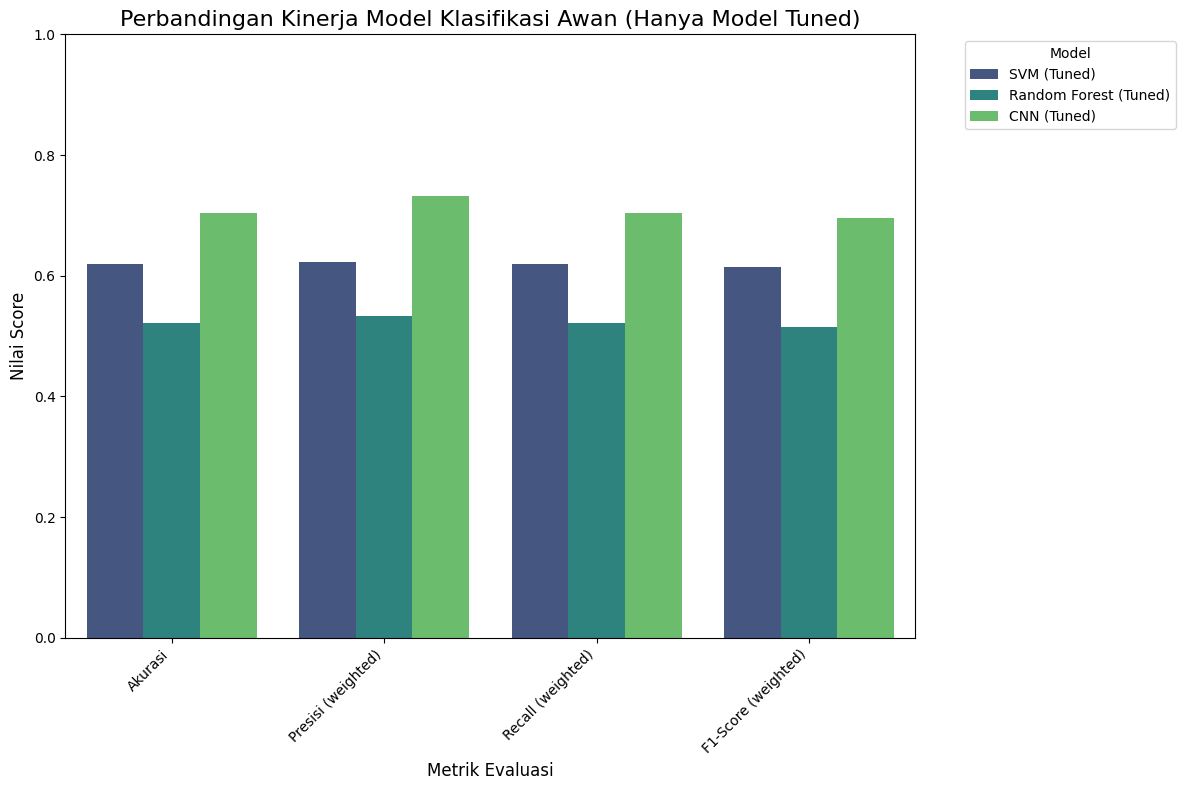

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter df_all_comparison to only include tuned models
df_tuned_only = df_all_comparison[df_all_comparison['Model'].str.contains('(Tuned)')]

# Melt DataFrame for better bar plot visualization, using df_tuned_only
df_melted_tuned = df_tuned_only.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 8)) # Adjusted figure size for fewer models
sns.barplot(x='Metric', y='Score', hue='Model', data=df_melted_tuned, palette='viridis')
plt.title('Perbandingan Kinerja Model Klasifikasi Awan (Hanya Model Tuned)', fontsize=16)
plt.xlabel('Metrik Evaluasi', fontsize=12)
plt.ylabel('Nilai Score', fontsize=12)
plt.ylim(0, 1) # Y-axis scale from 0 to 1 for metrics
plt.xticks(rotation=45, ha='right')
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left') # Adjust legend position
plt.tight_layout()
plt.show()